In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

In [3]:
url = "amz_uk_price_prediction_dataset.csv"

df = pd.read_csv(url)

In [4]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [5]:
#Create a crosstab between the product category and the isBestSeller status.

crosstab_result = pd.crosstab(df["category"], df["isBestSeller"])

In [6]:
crosstab_result.sort_values(True, ascending=False)

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
...,...,...
Downhill Ski Boots,1284,0
Digital Frames,774,0
Motorbike Chassis,107,0


In [7]:
#Are there categories where being a best-seller is more prevalent?

#Yes, the categories more prevalent in as best seller are the grocery, Health & personal care and baby

In [8]:
#Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

from scipy.stats import chi2_contingency

# Chi-square test for 'MSZoning' and 'SaleCondition'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

print(chi2_statistic, chi2_p_value)

print("Due to the extremely low P_value we can say that the 2 variables are significantly associated")

36540.20270061387 0.0
Due to the extremely low P_value we can say that the 2 variables are significantly associated


In [9]:
#Compute Cramér's V to understand the strength of association between best-seller status and category.

from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
print(association(crosstab_result, method="cramer"))

print("Even tho the variables are significantly associated in the statistical field in practical terms the Cramer's V formula tell us that this relationship is weak")

0.1222829439760564
Even tho the variables are significantly associated in the statistical field in practical terms the Cramer's V formula tell us that this relationship is weak


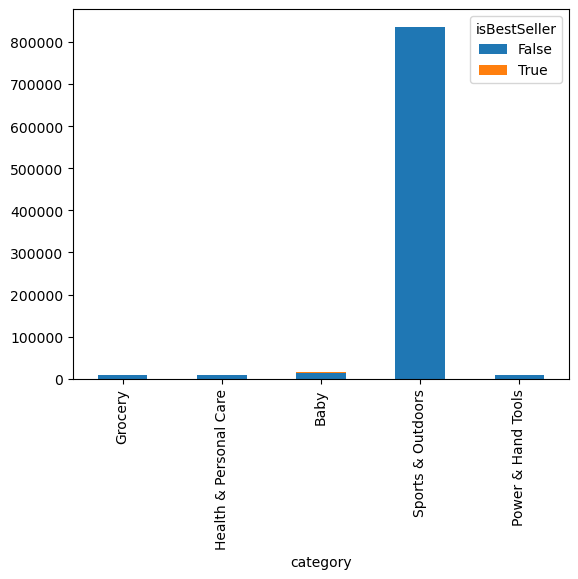

In [10]:
#Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

crosstab_result.sort_values(True, ascending=False).head().plot(kind="bar", stacked=True);

In [11]:
# remove the outliers

def remove_price_outliers(df, price_column):
    Q1 = df[price_column].quantile(0.25)
    Q3 = df[price_column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_no_outliers = df[(df[price_column] >= lower_bound) & (df[price_column] <= upper_bound)]

    return df_no_outliers

df_no_outliers = remove_price_outliers(df, 'price')

print("DataFrame without outliers:")
display(df_no_outliers)


DataFrame without outliers:


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [12]:
import matplotlib.pyplot as plt

In [13]:
top_categories = df_no_outliers['category'].value_counts().nlargest(20).index

In [14]:
df_top_categories = df_no_outliers[df_no_outliers['category'].isin(top_categories)]

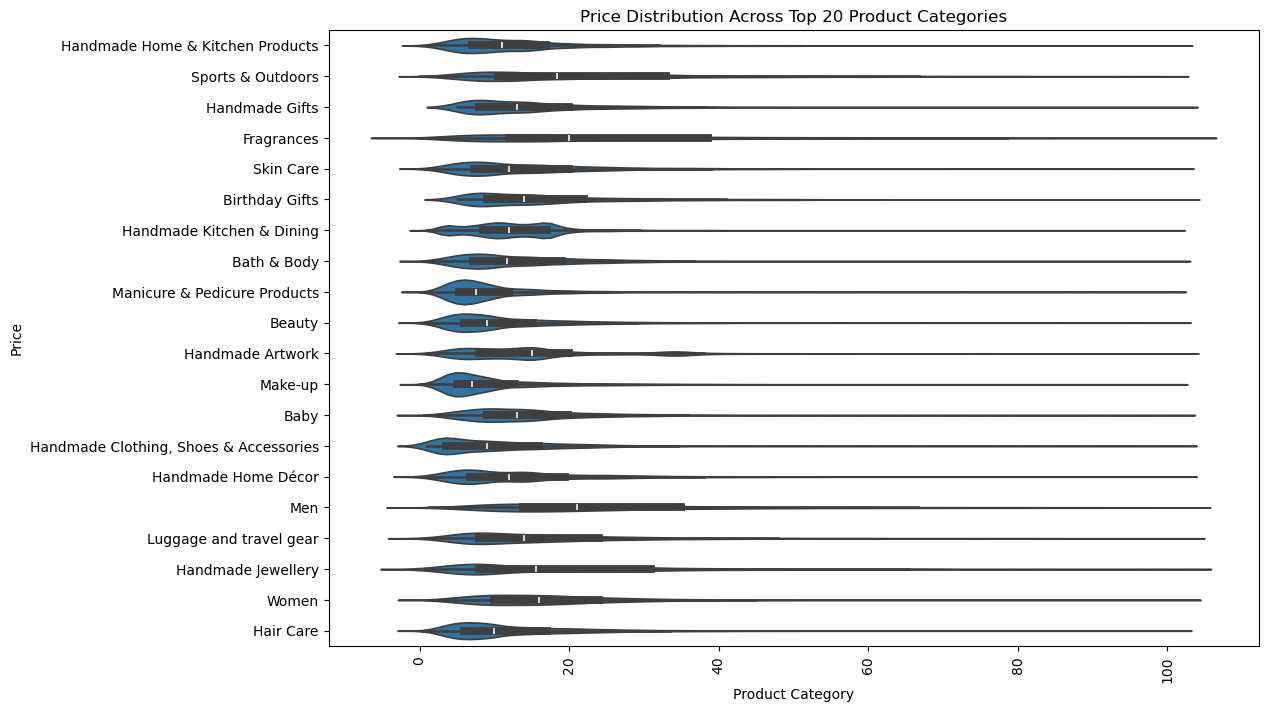

In [15]:
plt.figure(figsize=(12, 8))
sns.violinplot(y='category', x='price', data=df_top_categories)
plt.xticks(rotation=90)
plt.title('Price Distribution Across Top 20 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Price')
plt.show()

<Axes: xlabel='price', ylabel='category'>

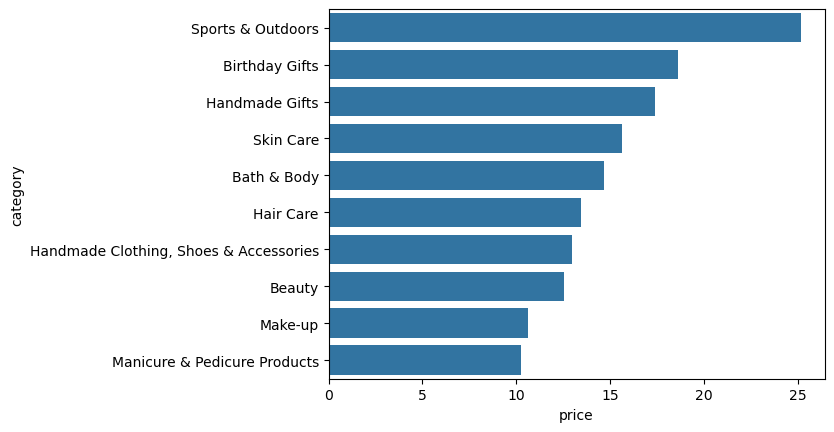

In [34]:
#Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

top_categories_2 = df_no_outliers['category'].value_counts().nlargest(10).index
df_top_categories_2 = df_no_outliers[df_no_outliers['category'].isin(top_categories_2)]

df_mean = df_top_categories_2.groupby("category")["price"].mean()
df_mean_sorted = df_mean.sort_values(ascending=False)
df_mean_sorted = df_mean_sorted.reset_index()
sns.barplot(data=df_mean_sorted, y="category", x="price")

In [31]:
#Which product category commands the highest average price? Don't filter here by top categories.

#The frangrances

<Axes: xlabel='stars', ylabel='category'>

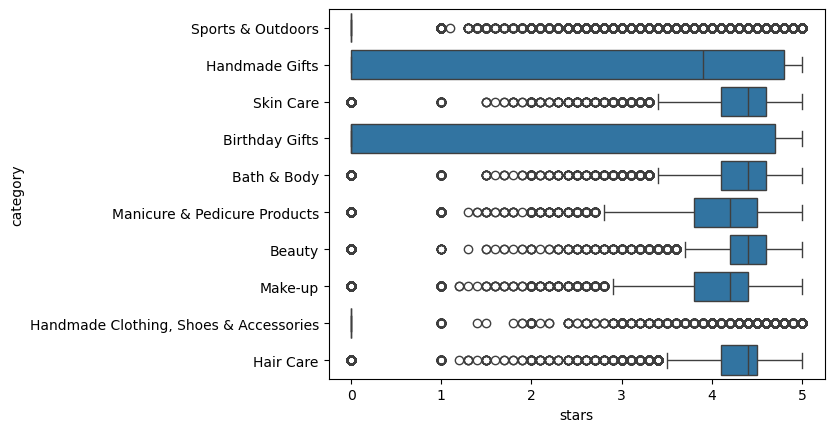

In [37]:
#Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

sns.boxplot(data=df_top_categories_2, y="category", x="stars")

In [38]:
#Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

#The handmade gifts

In [41]:
#Calculate the correlation coefficient between price and stars.

correlation = df['price'].corr(df['stars'])
correlation_sp = df['price'].corr(df['stars'], method='spearman')
correlation, correlation_sp

(-0.1249067326214861, -0.1331642546243379)

In [42]:
#Is there a significant correlation between product price and its rating?

#There is a small inverse correlation between both variables

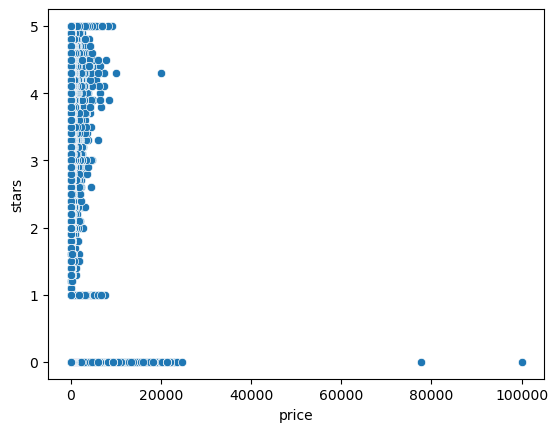

In [43]:
#Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

sns.scatterplot(data=df, x='price', y='stars');

#most of the top rating products are in low range prices and high price product tent to have less rating

<Axes: >

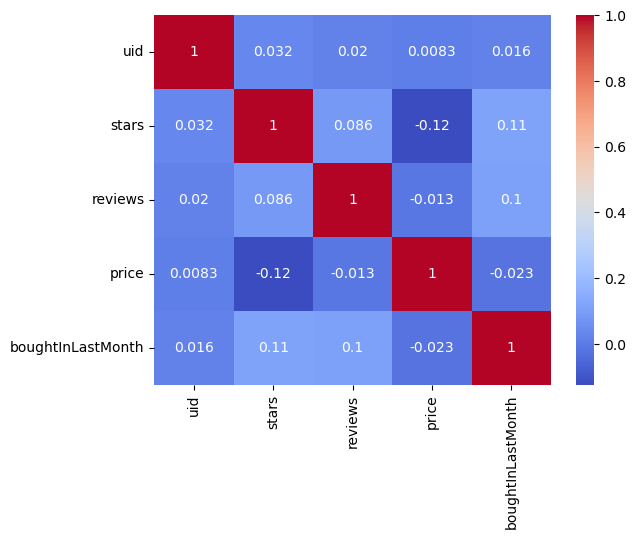

In [45]:
#Use a correlation heatmap to visualize correlations between all numerical variables.
potential_categorical_from_numerical = df.select_dtypes("number").loc[:, df.select_dtypes("number").nunique() < 20]
df_numerical = df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)
correlation_matrix = df_numerical.corr()

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

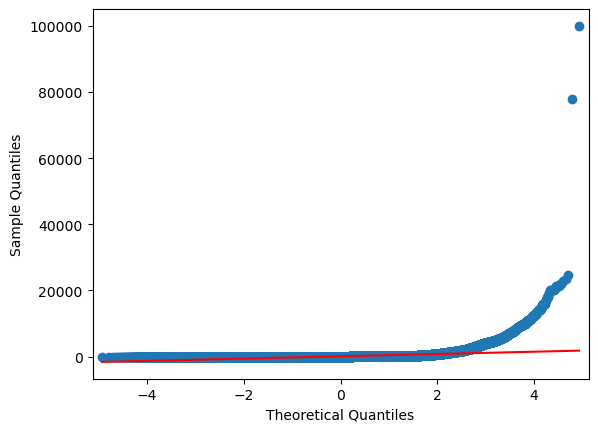

In [47]:
#Examine if product prices typically follow a normal distribution using a QQ plot.
import statsmodels.api as sm
sm.qqplot(df['price'], line='s');